# RSM8413 - Machine Learning Analytics 
### Group Assignment 1: COVID-19 Behaviour: K-Nearest Neighbour Python Source Code

## **[1]: Data Prep & EDA**

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(
    "../data/COVID-19BehaviorData_CAN2022.csv",
    low_memory=False)

# Convert whitespace-only cells to missing values
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Shape:", df.shape)
print(df.info())
print(df.head())

# Count fully missing columns
print("Empty columns:", df.isna().all().sum())

Shape: (6430, 512)
<class 'pandas.DataFrame'>
RangeIndex: 6430 entries, 0 to 6429
Columns: 512 entries, RecordNo to future_3
dtypes: float64(1), int64(3), str(508)
memory usage: 25.1 MB
None
   RecordNo           endtime    qweek i1_health i2_health i7a_health  \
0     41589  06/01/2022 18:02  week 44       NaN         0        NaN   
1     41731  03/01/2022 23:48  week 44       NaN         1        NaN   
2     41756  10/01/2022 04:53  week 44       NaN         0        NaN   
3     41846  01/01/2022 13:15  week 44       NaN         5        NaN   
4     41847  01/01/2022 19:12  week 44       NaN       150        NaN   

  i3_health i4_health i5_health_1 i5_health_2  ... vac_man_96 vac_man_99  \
0       NaN       NaN         NaN         NaN  ...         No         No   
1       NaN       NaN         NaN         NaN  ...         No         No   
2       NaN       NaN         NaN         NaN  ...        Yes         No   
3       NaN       NaN         NaN         NaN  ...         No     

In [3]:
df.head()

,RecordNo,endtime,qweek,i1_health,i2_health,i7a_health,i3_health,i4_health,i5_health_1,i5_health_2,...,vac_man_96,vac_man_99,q_other,had_covid,vac_boost_beyond,future_1,future_2,had_covid_2,long_covid,future_3
0,41589,06/01/2022 18:02,week 44,NaN,0,NaN,NaN,NaN,NaN,NaN,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,41731,03/01/2022 23:48,week 44,NaN,1,NaN,NaN,NaN,NaN,NaN,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,41756,10/01/2022 04:53,week 44,NaN,0,NaN,NaN,NaN,NaN,NaN,...,Yes,No,"Oui bar , restaurent",NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,41846,01/01/2022 13:15,week 44,NaN,5,NaN,NaN,NaN,NaN,NaN,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,41847,01/01/2022 19:12,week 44,NaN,150,NaN,NaN,NaN,NaN,NaN,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data Preprocessing

In [4]:
# Delete blank columns
df_clean = df.dropna(axis=1, how="all").copy()

print("New shape:", df_clean.shape)

missing_summary = (
    df_clean.isna().mean() * 100).sort_values(ascending=False)

print(missing_summary.head(30))

New shape: (6430, 159)
vac12_4       89.984448
vac12_3       89.984448
vac12_12      89.984448
vac12_96      89.984448
vac12_10      89.984448
vac12_9       89.984448
vac12_8       89.984448
vac12_7       89.984448
vac12_6       89.984448
vac12_5       89.984448
vac12_11      89.984448
vac12_13      89.984448
vac12_2       89.984448
vac12_1       89.984448
vac_1         89.984448
long_covid    87.636081
WAH_1         85.427683
WAH_3         85.427683
WAH_2         85.427683
Soc2_1        85.054432
Soc2_2        85.054432
Soc2_3        85.054432
Soc2_4        85.054432
Soc2_5        85.054432
Soc2_6        85.054432
had_covid     84.898911
future_3      84.432348
travel1_4     74.634526
Vent_1        74.634526
travel1_1     74.634526
dtype: float64


**The dataset includes a lot of missing values. The missing rate of remaining variables varies a lot.**

In [5]:
## Define the target variable, here we choose the vaccination status (vac)
# Examine the target variable
print(df_clean["vac"].value_counts(dropna=False))

print(
    df_clean["vac"].value_counts(normalize=True) * 100)

vac
Yes, two doses    5559
No, neither        644
Yes, one dose      227
Name: count, dtype: int64
vac
Yes, two doses    86.454121
No, neither       10.015552
Yes, one dose      3.530327
Name: proportion, dtype: float64


In [6]:
#Create binary target variable
df_clean["vac_binary"] = df_clean["vac"].map({
    "Yes, two doses": 1,
    "Yes, one dose": 0,
    "No, neither": 0})

# Check the distribution
print(df_clean["vac_binary"].value_counts())
print(df_clean["vac_binary"].value_counts(normalize=True) * 100)

# Check for missing target values
print("Missing target:", df_clean["vac_binary"].isna().sum())

vac_binary
1    5559
0     871
Name: count, dtype: int64
vac_binary
1    86.454121
0    13.545879
Name: proportion, dtype: float64
Missing target: 0


In [34]:
#Create binary target variable
df_clean["vac_binary"] = df_clean["vac"].map({
    "Yes, two doses": 1,
    "Yes, one dose": 0,
    "No, neither": 0})

# Check the distribution
print(df_clean["vac_binary"].value_counts())
print(df_clean["vac_binary"].value_counts(normalize=True) * 100)

# Check for missing target values
print("Missing target:", df_clean["vac_binary"].isna().sum())

vac_binary
1    5559
0     871
Name: count, dtype: int64
vac_binary
1    86.454121
0    13.545879
Name: proportion, dtype: float64
Missing target: 0


In [7]:
##Predictor Selection
# Inspect available variables for predictor selection
variable_summary = pd.DataFrame({
    "Variable": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Missing (%)": (
        df_clean.isna().mean().values * 100
    ).round(2),
    "Unique Values": df_clean.nunique().values
})

# Exclude the newly created target from candidate predictors
variable_summary = variable_summary[
    ~variable_summary["Variable"].isin(
        ["vac", "vac_binary"])]

print(variable_summary.to_string(index=False))

           Variable Data Type  Missing (%)  Unique Values
           RecordNo     int64         0.00           6430
            endtime       str         0.00           5902
              qweek       str         0.00              7
          i2_health       str        31.21             64
          i9_health       str         0.00              3
         i11_health       str         0.00              6
       i12_health_1       str         0.00              5
       i12_health_2       str        15.57              5
       i12_health_3       str         0.00              5
       i12_health_4       str         0.00              5
       i12_health_5       str         0.00              5
       i12_health_6       str         0.00              5
       i12_health_7       str         0.00              5
       i12_health_8       str         0.00              5
       i12_health_9       str        55.99              5
      i12_health_10       str        68.40              5
      i12_heal

In [8]:
# Define baseline predictor variables
features = ["age", "gender", "region", "employment_status", "household_children", 
            "vac7", "r1_8"]  

# Create predictor matrix and target vector
X = df_clean[features].copy()
y = df_clean["vac_binary"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

# Verify missing values
print("\nMissing values:")
print(X.isna().sum())

# Check variable types
print("\nData types:")
print(X.dtypes)

Predictor shape: (6430, 7)
Target shape: (6430,)

Missing values:
age                   0
gender                0
region                0
employment_status     0
household_children    0
vac7                  0
r1_8                  0
dtype: int64

Data types:
age                   int64
gender                  str
region                  str
employment_status       str
household_children      str
vac7                    str
r1_8                    str
dtype: object



### Predictor Selection — Baseline Feature Set

For the initial KNN classification model, we selected five predictor variables:

- **Age**
- **Gender**
- **Region**
- **Employment Status**
- **Household Children**
- **Trust in COVID-19 Vaccines (vac_7)**
- **Perceived Protection in COVID-19 Vaccines (r1_8)**

#### Selection Rationale

These variables were selected based on three main considerations:

1. **Data Completeness:** All seven variables have 0% missing values, allowing us to retain all 6,430 observations without additional imputation at this stage.

2. **Interpretability and Business Relevance:** The selected variables represent demographic, household, and personal perceptions on the vaccine itself.

3. **Model Simplicity:** KNN is sensitive to feature dimensionality because predictions rely on distances between observations. Starting with a smaller, interpretable feature set helps limit unnecessary dimensionality and provides a clear baseline for subsequent model development.

#### Excluded Variables

- **Identifiers and Metadata:** Variables such as `RecordNo` and `endtime` were excluded because they are not suitable as direct predictors in the initial model.
- **Vaccination-Related Variables:** Variables such as `vac_boost_*` and `vac12_*` were temporarily excluded due to potential target leakage.
- **Health and Behavioral Variables:** While r1_8 (perceived protection from COVID-19 vaccination) was included as a predictor, other variables within the r1_* and i12_health_* groups were excluded to limit model complexity and reduce potential redundancy among closely related health attitudes and behaviors. These variables may be explored in future analyses to determine whether they provide additional predictive value..
- **Variables with High Missingness:** Variables with substantial missing values were deferred pending further assessment of their missingness patterns and potential predictive value.

#### Next Steps

This feature set serves as an **initial baseline rather than the final predictor set**. Health and behavioral variables may be excluded after reviewing their definitions, missingness patterns, and relationships with the target variable.

Categorical predictors will be one-hot encoded, while numerical predictors will be scaled to ensure that differences in measurement scales do not disproportionately influence KNN distance calculations. Preprocessing will be fitted using training data only to avoid data leakage.

### Train/Test Split

The dataset was divided into a training set (80%) and a test set (20%), resulting in 5,144 and 1,286 observations, respectively.

Stratified sampling was applied to preserve the original target distribution in both subsets, given the substantial class imbalance.

A fixed random state (`random_state=42`) was used to ensure reproducibility.

The training set will be used for preprocessing, model fitting, and hyperparameter tuning through cross-validation. The test set will be reserved for final model evaluation to assess generalization performance.


In [9]:
#Data split
from sklearn.model_selection import train_test_split

#Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

#Verify target distribution
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training set: (5144, 7)
Testing set: (1286, 7)

Training target distribution:
vac_binary
1    86.450233
0    13.549767
Name: proportion, dtype: float64

Testing target distribution:
vac_binary
1    86.469673
0    13.530327
Name: proportion, dtype: float64


### One-Hot Encoding and Standardization

Categorical predictors were transformed into dummy variables using one-hot encoding (`drop_first=False`). All categories were retained, as KNN does not require a reference category to be omitted.

Numerical predictors (`age`) were standardized using Z-score standardization to reduce the influence of differences in measurement scales on KNN distance calculations.

The scaling parameters were estimated using the training data only and subsequently applied to the test data to prevent data leakage.

The same set of encoded feature columns was maintained across the training and test sets.

First, we inspected the unique survey responses to identify variables requiring numerical encoding. The categorical responses for `vac7` and `r1_8` were converted into ordinal numerical values while preserving their original ordering. The original responses and their corresponding encoded values are presented in the tables below.

In [10]:
# Encode survey responses
df_clean["vac7_num"] = df_clean["vac7"].map({
    "Not at all": 1,
    "A little": 2,
    "Moderately": 3,
    "Very much": 4
})

df_clean["r1_8_num"] = pd.to_numeric(
    df_clean["r1_8"].astype("string").str.extract(r"^(\d+)")[0],
    errors="coerce"
)

# Display clean frequency tables
for col, encoded in [
    ("vac7", "vac7_num"),
    ("r1_8", "r1_8_num")
]:
    summary = (
        df_clean.groupby([encoded, col], dropna=False)
        .size()
        .reset_index(name="Count")
        .sort_values(encoded)
    )

    summary["Percentage (%)"] = (
        summary["Count"] / len(df_clean) * 100
    ).round(2)

    summary = summary.rename(columns={
        encoded: "Encoded Value",
        col: "Original Response"
    })

    print(f"\n{col} — Response Distribution")
    display(summary[
        ["Original Response", "Encoded Value",
         "Count", "Percentage (%)"]
    ])



vac7 — Response Distribution


,Original Response,Encoded Value,Count,Percentage (%)
0,Not at all,1,754,11.73
1,A little,2,1075,16.72
2,Moderately,3,2388,37.14
3,Very much,4,2213,34.42



r1_8 — Response Distribution


,Original Response,Encoded Value,Count,Percentage (%)
0,1 – Disagree,1,803,12.49
1,2,2,215,3.34
2,3,3,343,5.33
3,4,4,787,12.24
4,5,5,842,13.09
5,6,6,968,15.05
6,7 - Agree,7,2472,38.44


In [11]:

from sklearn.preprocessing import StandardScaler

# Define numerical and categorical predictors
numeric_features = [
    "age",
    "vac7_num",
    "r1_8_num"
]

categorical_features = [
    "gender",
    "region",
    "employment_status",
    "household_size",
    "household_children"
]

# Select the encoded predictors
feature_cols = numeric_features + categorical_features

# Preserve the original train/test split
X_train = df_clean.loc[X_train.index, feature_cols].copy()
X_test = df_clean.loc[X_test.index, feature_cols].copy()

# Step 1: One-hot encoding
# Keep all dummy variables, as recommended for KNN
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_features,
    drop_first=False,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_features,
    drop_first=False,
    dtype=int
)

# Ensure test set has the same columns as training set
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Step 2: Z-score standardization
# Fit scaler on training data only
scaler = StandardScaler()

X_train_encoded[numeric_features] = scaler.fit_transform(
    X_train_encoded[numeric_features]
)

X_test_encoded[numeric_features] = scaler.transform(
    X_test_encoded[numeric_features]
)

# Step 3: Check processed data
print("Processed training shape:", X_train_encoded.shape)
print("Processed testing shape:", X_test_encoded.shape)

print("\nFirst 5 rows:")
display(X_train_encoded.head())

print("\nNumerical feature means:")
print(X_train_encoded[numeric_features].mean().round(4))

print("\nNumerical feature standard deviations:")
print(X_train_encoded[numeric_features].std(ddof=0).round(4))


Processed training shape: (5144, 42)
Processed testing shape: (1286, 42)

First 5 rows:


,age,vac7_num,r1_8_num,gender_Female,gender_Male,region_Alberta,region_British Columbia / Colombie Britanique,region_Manitoba,region_New Brunswick / Nouveau-Brunswick,region_Newfoundland & Labrador / Terre-Neuve-et-Labrador,...,household_size_Don't know,household_size_Prefer not to say,household_children_0,household_children_1,household_children_2,household_children_3,household_children_4,household_children_5 or more,household_children_Don't know,household_children_Prefer not to say
4740,-0.200958,-1.978124,-1.980685,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3436,-1.581693,0.049064,0.913268,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3968,0.682712,1.062658,0.913268,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
5998,0.351336,0.049064,0.913268,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
5354,-0.698023,-1.978124,-1.498359,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0



Numerical feature means:
age         0.0
vac7_num   -0.0
r1_8_num   -0.0
dtype: float64

Numerical feature standard deviations:
age         1.0
vac7_num    1.0
r1_8_num    1.0
dtype: float64


### EDA

Exploratory Data Analysis (EDA) is conducted using the training set only (5,144 observations) to keep the test set independent for final model evaluation.

We first examine the distribution of our binary target variable, `vac_binary`:

- **Class 1:** Individuals who received two doses of a COVID-19 vaccine.
- **Class 0:** Individuals who received fewer than two doses.

The objective is to identify potential class imbalance and understand its implications for subsequent KNN classification.

### EDA 1
#### Key Findings — Target Distribution

Among the 5,144 observations in the training set, 4,447 (86.45%) had received two doses of a COVID-19 vaccine, while 697 (13.55%) had received fewer than two doses.

This indicates substantial class imbalance. A classifier that always predicts the majority class would achieve approximately 86.45% accuracy without identifying any individuals in the minority class.

Therefore, accuracy alone may be misleading. Additional metrics, particularly recall and F1 score for individuals with fewer than two doses and and other sampling approaches, should be considered when evaluating the KNN model.

EDA dataset shape: (5144, 9)

Target Distribution:
                      Count  Percentage (%)
Fewer than Two Doses    697           13.55
Two Doses              4447           86.45


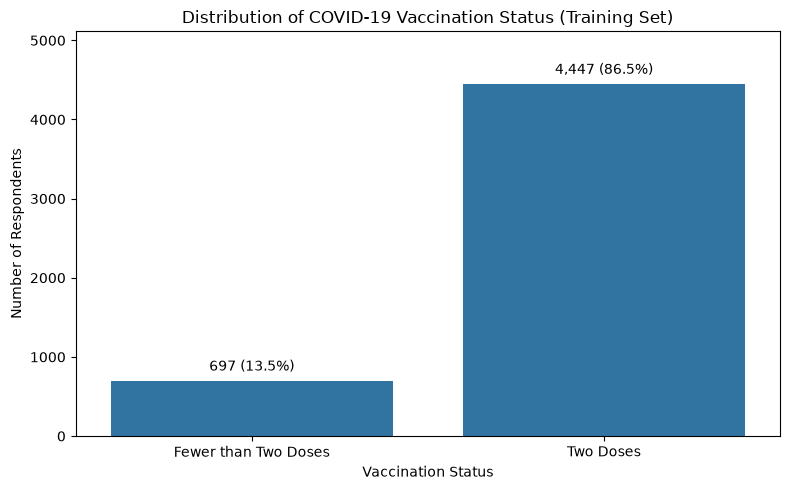

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Step 1: Create EDA dataset from training data only
eda_df = X_train.copy()
eda_df["vac_binary"] = y_train

print("EDA dataset shape:", eda_df.shape)

#Step 2: Examine target distribution
target_counts = eda_df["vac_binary"].value_counts().sort_index()
target_percentages = (
    eda_df["vac_binary"].value_counts(normalize=True)
    .sort_index() * 100)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages.round(2)})

target_summary.index = [
    "Fewer than Two Doses",
    "Two Doses"]

print("\nTarget Distribution:")
print(target_summary)

#Step 3: Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=eda_df,
    x="vac_binary",
    order=[0, 1])

ax.set_title(
    "Distribution of COVID-19 Vaccination Status (Training Set)")
ax.set_xlabel("Vaccination Status")
ax.set_ylabel("Number of Respondents")

ax.set_xticks([0, 1])
ax.set_xticklabels([
    "Fewer than Two Doses",
    "Two Doses"])

#Add counts and percentages above bars
for i, bar in enumerate(ax.patches):
    count = int(bar.get_height())
    percentage = count / len(eda_df) * 100

    ax.annotate(
        f"{count:,} ({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points")

plt.ylim(0, target_counts.max() * 1.15)
plt.tight_layout()
plt.show()



### EDA 2
#### Key Findings — Age vs Vaccination Status

Two-dose vaccination rates vary across age groups. Respondents aged 60 and above have the highest vaccination rate (93.06%), while those aged 30–44 have the lowest (80.62%), representing a difference of approximately 12.44 percentage points.

Although vaccination rates are generally higher among older respondents, the relationship is not strictly monotonic, as the under-30 group has a slightly higher vaccination rate (82.35%) than the 30–44 group.

These findings suggest that age may be a relevant predictor of vaccination status. From a public health perspective, younger and middle-aged groups may warrant further investigation when identifying populations with lower two-dose vaccination coverage. However, these descriptive associations do not establish causality.

           count      mean  Vaccination Rate (%)
age_group                                       
Under 30     895  0.823464             82.346369
30-44       1254  0.806220             80.622010
45-59       1150  0.853913             85.391304
60+         1845  0.930623             93.062331


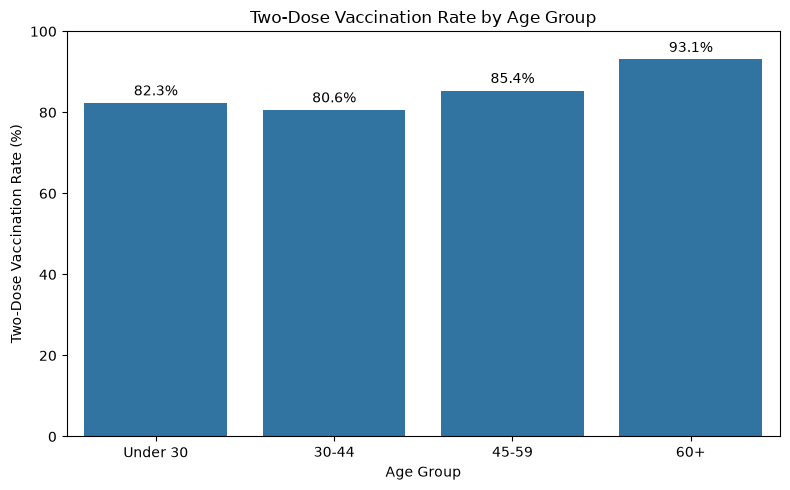

In [13]:
#EDA 2: Age vs Vaccination Status

#Create age groups
eda_df["age_group"] = pd.cut(
    eda_df["age"],
    bins=[0, 29, 44, 59, float("inf")],
    labels=["Under 30", "30-44", "45-59", "60+"],
    include_lowest=True)

#Calculate vaccination rates by age group
age_summary = eda_df.groupby(
    "age_group",
    observed=True
)["vac_binary"].agg(["count", "mean"])

age_summary["Vaccination Rate (%)"] = (
    age_summary["mean"] * 100)

print(age_summary)

#Plot vaccination rate by age group
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=age_summary.reset_index(),
    x="age_group",
    y="Vaccination Rate (%)")

ax.set_title("Two-Dose Vaccination Rate by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Two-Dose Vaccination Rate (%)")
ax.set_ylim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

### EDA 3: Region vs Vaccination Status

We examine the relationship between geographic region and two-dose COVID-19 vaccination status to identify potential regional differences in vaccination coverage.

Vaccination rates are calculated as the percentage of respondents who received two doses within each region. For visualization purposes, regions with fewer than 30 observations are excluded to reduce the influence of very small sample sizes. However, these observations remain in the dataset for subsequent modeling.

#### Key Findings — Region vs Vaccination Status

Two-dose vaccination rates vary across Canadian regions. Among regions with at least 30 observations, Alberta has the lowest vaccination rate (80.35%), followed by Manitoba (83.76%). Nova Scotia has the highest rate (89.60%), while Ontario (87.06%) and Quebec (88.54%) are slightly above the overall training-set average of 86.45%.

The difference between Alberta and Nova Scotia is approximately 9.25 percentage points, suggesting a potential association between geographic location and vaccination status.

However, some regions have very small sample sizes, including Nunavut (n = 3), Yukon (n = 10), and Prince Edward Island (n = 28). Their vaccination rates should be interpreted cautiously due to sampling variability.

The findings suggest that regional differences in two-dose vaccination rates are relatively small, with most regions reporting rates between 80% and 90%. This indicates that region may have limited predictive value for the KNN model, as vaccination rates are fairly consistent across regions. However, further analysis is needed to determine whether region provides additional predictive information when combined with other variables. These descriptive results are unweighted and do not establish causal relationships.

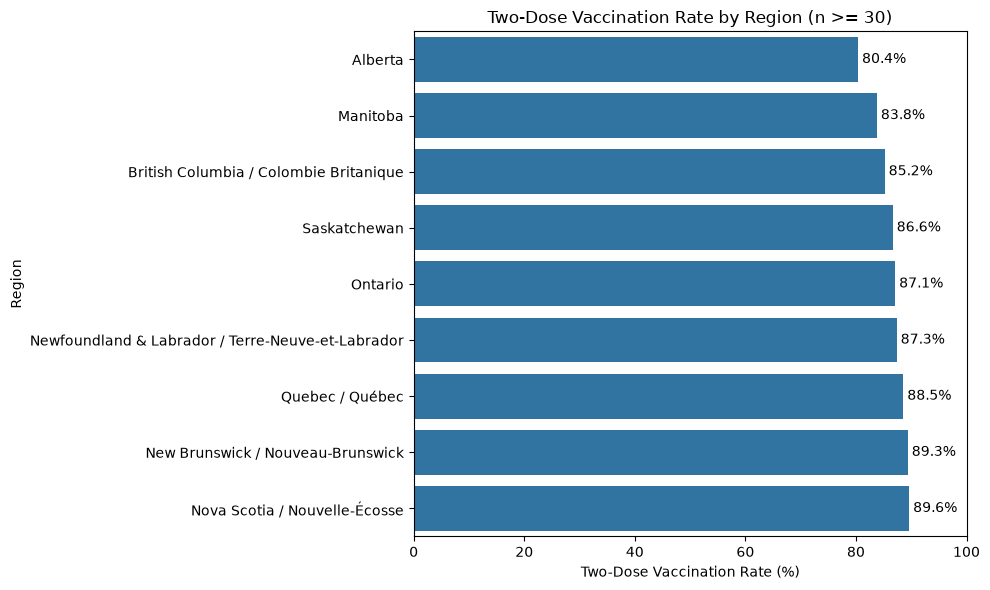

In [14]:
#EDA 3: Region vs Vaccination Status
# Exclude regions with fewer than 30 observations (I ran a full regions code before, but I found some regions only 
#include few observations)
#from visualization only

# Calculate vaccination rates by region
region_summary = eda_df.groupby(
    "region"
)["vac_binary"].agg(["count", "mean"])

region_summary["Vaccination Rate (%)"] = (
    region_summary["mean"] * 100)

region_summary = region_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)


region_plot = region_summary[
    region_summary["count"] >= 30
].copy()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=region_plot.reset_index(),
    x="Vaccination Rate (%)",
    y="region")

ax.set_title(
    "Two-Dose Vaccination Rate by Region (n >= 30)")
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Region")
ax.set_xlim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

### EDA 4: Employment Status vs Vaccination Status

We examine the relationship between employment status and two-dose COVID-19 vaccination coverage to identify potential differences across socioeconomic groups.

Vaccination rates are calculated as the percentage of respondents who received two doses within each employment category.

This analysis aims to assess whether employment status may provide useful predictive information for the KNN model. Since employment status may be associated with age, observed differences will be interpreted as descriptive associations rather than causal effects.


#### Key Findings — Employment Status vs Vaccination Status

Two-dose vaccination rates differ substantially across employment groups. Retired respondents have the highest vaccination rate (93.67%), while unemployed respondents have the lowest (70.63%), representing a difference of approximately 23.04 percentage points.

Full-time employed respondents also show a relatively high vaccination rate (88.31%), compared with 81.45% among part-time employed respondents and 70.63% among unemployed respondents.

These findings suggest that employment status may provide useful predictive information for the KNN model. From a public health perspective, unemployed individuals may represent a group warranting further investigation regarding lower two-dose vaccination coverage.

However, employment status may be associated with other demographic characteristics, particularly age. The high vaccination rate among retired respondents may partly reflect their age distribution. Therefore, the observed differences should be interpreted as descriptive associations rather than causal relationships.

                      count      mean  Vaccination Rate (%)
employment_status                                          
Unemployed              429  0.706294             70.629371
Other                   211  0.725118             72.511848
Not working             422  0.812796             81.279621
Part time employment    512  0.814453             81.445312
Full time student       324  0.876543             87.654321
Full time employment   1745  0.883095             88.309456
Retired                1501  0.936709             93.670886


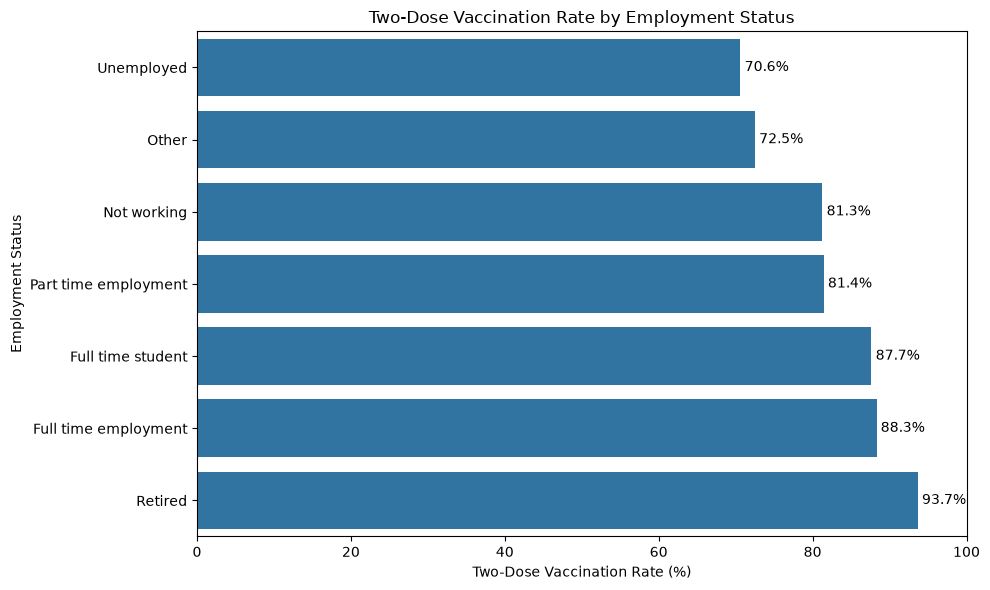

In [15]:
#EDA 4: Employment Status vs Vaccination Status

#Calculate vaccination rates by employment status
employment_summary = eda_df.groupby(
    "employment_status"
)["vac_binary"].agg(["count", "mean"])

employment_summary["Vaccination Rate (%)"] = (
    employment_summary["mean"] * 100)

#Sort by vaccination rate
employment_summary = employment_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)

print(employment_summary)

#Plot vaccination rates by employment status
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=employment_summary.reset_index(),
    x="Vaccination Rate (%)",
    y="employment_status")

ax.set_title(
    "Two-Dose Vaccination Rate by Employment Status")
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Employment Status")
ax.set_xlim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

### EDA 5: Gender vs Vaccination Status

We examine the relationship between gender and two-dose COVID-19 vaccination status using the training dataset.

Vaccination rates are calculated as the percentage of respondents who received two doses within each gender category.

The objective is to identify whether vaccination coverage differs between male and female respondents and to assess whether gender may provide useful information for subsequent KNN classification.


#### Key Findings — Gender vs Vaccination Status

Two-dose vaccination rates are nearly identical between male and female respondents. Female respondents have a vaccination rate of 86.59%, compared with 86.28% among male respondents, representing a difference of only 0.31 percentage points.

This suggests that gender has a weak marginal association with vaccination status in the training sample and may offer limited standalone predictive information.

Gender was included in the exploratory data analysis as a potential predictor. However, its predictive relevance will be further assessed during feature selection and model evaluation, and it may be excluded from the final KNN model if it does not provide meaningful improvements in predictive performance. 

        count      mean  Vaccination Rate (%)
gender                                       
Male     2369  0.862811             86.281131
Female   2775  0.865946             86.594595


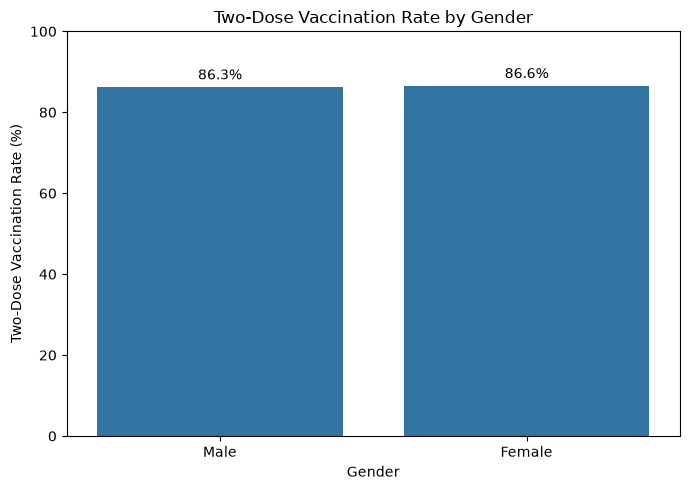

In [16]:
#EDA 5: Gender vs Vaccination Status

#Calculate vaccination rates by gender
gender_summary = eda_df.groupby(
    "gender"
)["vac_binary"].agg(["count", "mean"])

gender_summary["Vaccination Rate (%)"] = (
    gender_summary["mean"] * 100)

#Sort by vaccination rate
gender_summary = gender_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)

print(gender_summary)

# Plot vaccination rates by gender
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=gender_summary.reset_index(),
    x="gender",
    y="Vaccination Rate (%)")

ax.set_title("Two-Dose Vaccination Rate by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Two-Dose Vaccination Rate (%)")
ax.set_ylim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

### EDA 6: Household Children vs Vaccination Status

We examine the relationship between the number of children in a household and two-dose COVID-19 vaccination status using the training dataset.

Vaccination rates are calculated as the percentage of respondents who received two doses within each household children category.

The objective is to investigate whether household composition, particularly the presence and number of children, is associated with vaccination status and whether this variable may provide additional predictive information for KNN classification.

Categories with small sample sizes and non-numeric responses will be interpreted cautiously.


#### Key Findings — Household Children vs Vaccination Status

Two-dose vaccination rates vary across households with different numbers of children. Respondents living in households without children have the highest vaccination rate (89.41%), while those living in households with three children have a substantially lower rate (74.87%), representing a difference of approximately 14.54 percentage points.

However, vaccination rates do not decrease consistently as the number of children increases. For example, households with two children have a higher vaccination rate (83.54%) than those with one child (81.21%).

These findings suggest that household composition may be associated with vaccination status. However, the relationship may partly reflect differences in age and employment status across households.

Categories with very small sample sizes, particularly "Don't know" (n = 8), should be interpreted cautiously.

Household children will be retained as a baseline predictor, although its additional predictive value beyond household size and other demographic variables remains to be evaluated.

                    count      mean  Vaccination Rate (%)
household_children                                       
Don't know              8  0.625000             62.500000
3                     195  0.748718             74.871795
Prefer not to say      74  0.756757             75.675676
4                     136  0.779412             77.941176
5 or more              83  0.783133             78.313253
1                     660  0.812121             81.212121
2                     559  0.835420             83.542039
0                    3429  0.894138             89.413823


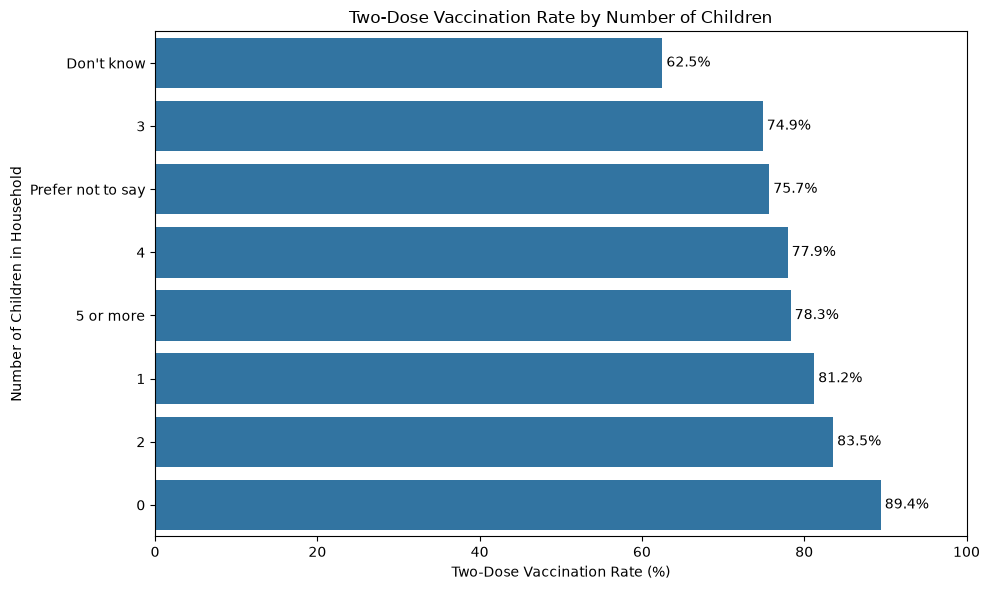

In [17]:
#EDA 6: Household Children vs Vaccination Status

#Calculate vaccination rates by number of children
children_summary = eda_df.groupby(
    "household_children"
)["vac_binary"].agg(["count", "mean"])

children_summary["Vaccination Rate (%)"] = (
    children_summary["mean"] * 100)

#Sort by vaccination rate
children_summary = children_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)

print(children_summary)

# Plot vaccination rates by number of children
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=children_summary.reset_index(),
    x="Vaccination Rate (%)",
    y="household_children")

ax.set_title(
    "Two-Dose Vaccination Rate by Number of Children")
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Number of Children in Household")
ax.set_xlim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### EDA 7: Trust in COVID-19 Vaccine vs. Vaccination Status

We examine the relationship between trust in COVID-19 vaccines (`vac7`) and two-dose vaccination status using the training dataset.

Vaccination rates are calculated as the percentage of respondents who received two doses within each vaccine trust category: "Not at all," "A little," "Moderately," and "Very much."

The objective is to investigate whether higher levels of vaccine trust are associated with higher vaccination rates and whether vaccine trust may serve as a meaningful predictor for KNN classification.

#### Key Findings — Trust in COVID-19 Vaccine vs. Vaccination Status

Two-dose vaccination rates increase consistently with vaccine trust, from 35.24% among respondents reporting no trust to 98.16% among those reporting very high trust, a difference of 62.92 percentage points. The largest increase occurs between "Not at all" (35.24%) and "A little" (79.77%). Vaccination rates continue to rise to 94.38% among respondents with moderate trust, before increasing more gradually to 98.16% among those with very high trust.

The variation across trust levels indicates that vaccine trust may help distinguish between vaccination groups, making it a useful candidate for KNN classification. Notably, vaccination rates exceed 94% among respondents reporting moderate or very high trust, suggesting that differences are most pronounced at lower trust levels.


          count      mean  Vaccination Rate (%) Trust Level
vac7_num                                                   
1           593  0.352445             35.244519  Not at all
2           855  0.797661             79.766082    A little
3          1904  0.943803             94.380252  Moderately
4          1792  0.981585             98.158482   Very much


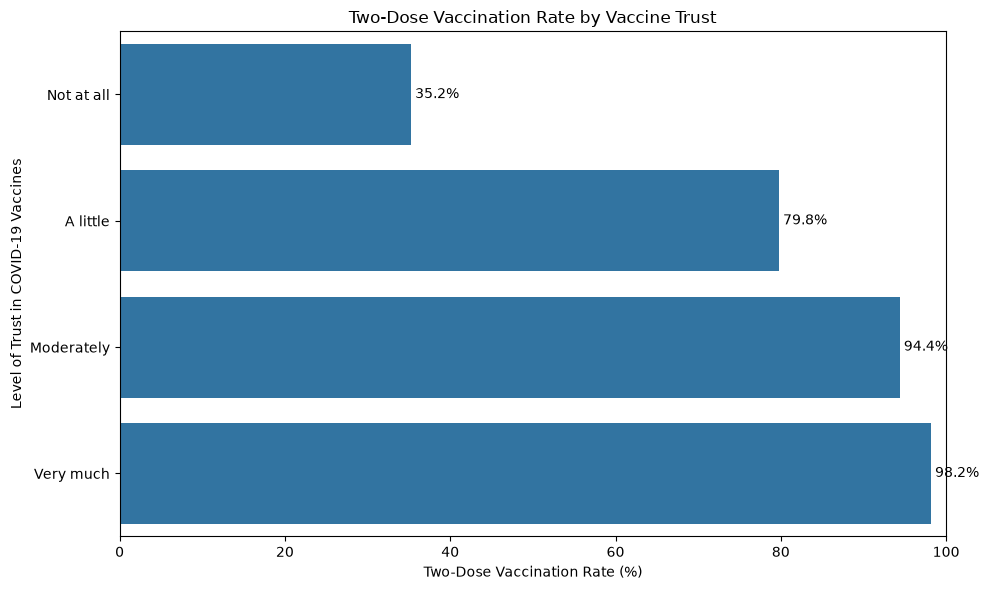

In [18]:
# EDA 7: Vaccine Trust vs Vaccination Status

# Calculate vaccination rates by vaccine trust
trust_summary = eda_df.groupby(
    "vac7_num"
)["vac_binary"].agg(["count", "mean"])

trust_summary["Vaccination Rate (%)"] = (
    trust_summary["mean"] * 100
)

# Map numerical values to response labels
trust_summary["Trust Level"] = trust_summary.index.map({
    1: "Not at all",
    2: "A little",
    3: "Moderately",
    4: "Very much"
})

print(trust_summary)

# Plot vaccination rates by vaccine trust
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=trust_summary.reset_index(),
    x="Vaccination Rate (%)",
    y="Trust Level"
)

ax.set_title(
    "Two-Dose Vaccination Rate by Vaccine Trust"
)
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Level of Trust in COVID-19 Vaccines")
ax.set_xlim(0, 100)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### EDA 8: Perceived Protection from COVID-19 Vaccine vs Vaccination Status

We examine the relationship between perceived protection from COVID-19 vaccination (`r1_8`) and two-dose vaccination status using the training dataset.

Vaccination rates are calculated as the percentage of respondents who received two doses within each agreement level, ranging from 1 (Disagree) to 7 (Agree).

The objective is to investigate whether respondents' beliefs about the protective benefits of vaccination are associated with vaccination status and whether this variable may provide additional predictive information for KNN classification.

#### Key Findings — Perceived Vaccine Protection vs Vaccination Status

Two-dose vaccination rates increase consistently with stronger agreement that vaccination provides protection, from 41.46% among respondents who strongly disagree (Level 1) to 97.75% among those who strongly agree (Level 7), a difference of 56.29 percentage points. The largest increase occurs between Levels 1 (41.46%) and 2 (70.78%). Vaccination rates continue to rise across subsequent levels, reaching 91.61% at Level 5 and 96.55% at Level 6.

The variation across agreement levels suggests that perceived vaccine protection may help distinguish between vaccination groups, making it a relevant candidate for KNN classification. However, because this variable measures a concept related to vaccine trust (`vac7`), their potential overlap should be considered when evaluating its additional predictive contribution.

          count      mean  Vaccination Rate (%) Agreement Level
r1_8_num                                                       
1           644  0.414596             41.459627    1 - Disagree
2           154  0.707792             70.779221               2
3           273  0.783883             78.388278               3
4           626  0.861022             86.102236               4
5           691  0.916064             91.606368               5
6           754  0.965517             96.551724               6
7          2002  0.977522             97.752248       7 - Agree


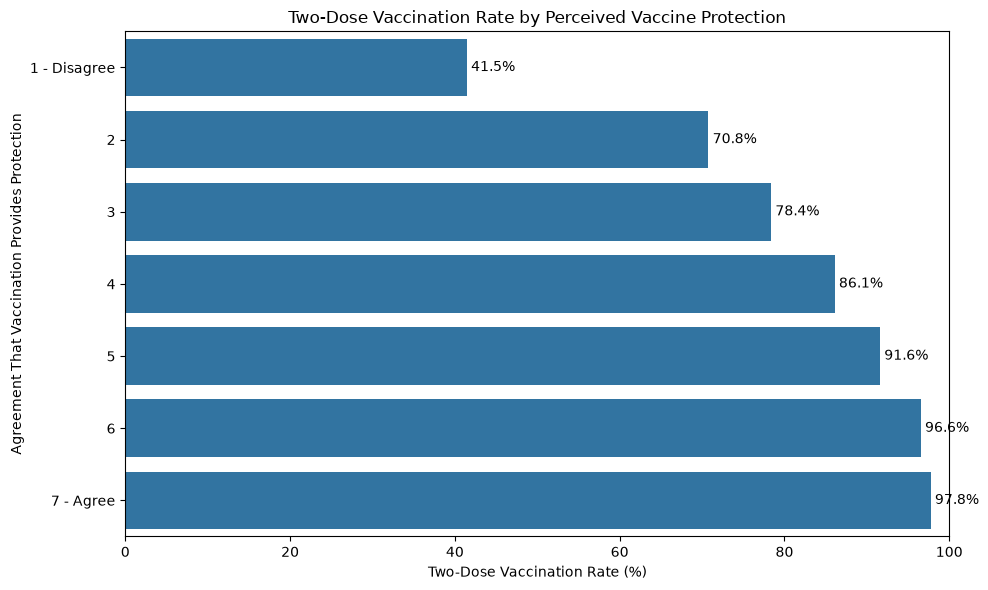

In [19]:

# EDA 8: Perceived Vaccine Protection vs Vaccination Status

# Calculate vaccination rates by perceived protection
protection_summary = eda_df.groupby(
    "r1_8_num"
)["vac_binary"].agg(["count", "mean"])

protection_summary["Vaccination Rate (%)"] = (
    protection_summary["mean"] * 100
)

# Map numerical values to response labels
protection_summary["Agreement Level"] = protection_summary.index.map({
    1: "1 - Disagree",
    2: "2",
    3: "3",
    4: "4",
    5: "5",
    6: "6",
    7: "7 - Agree"
})

print(protection_summary)

# Plot vaccination rates by perceived protection
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=protection_summary.reset_index(),
    x="Vaccination Rate (%)",
    y="Agreement Level"
)

ax.set_title(
    "Two-Dose Vaccination Rate by Perceived Vaccine Protection"
)
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Agreement That Vaccination Provides Protection")
ax.set_xlim(0, 100)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()



### EDA 9: Age × Employment Status vs Vaccination Status

We conduct a multivariate exploratory analysis to investigate whether differences in two-dose vaccination rates across employment groups persist within the same age categories.

Vaccination rates are calculated for each combination of age group and employment status using the training dataset.

Previous EDA findings indicated that older and retired respondents had higher vaccination rates, while unemployed respondents had lower rates. This analysis examines whether these patterns may partly reflect differences in age composition.

To avoid misleading interpretations from very small samples, combinations with fewer than 30 observations are masked in the heatmap. All observations remain in the dataset for subsequent modeling.


#### Key Findings — Age × Employment Status vs Vaccination Status

The multivariate analysis indicates that differences in two-dose vaccination rates across employment groups persist within age categories.

Full-time employed respondents consistently have higher vaccination rates than unemployed respondents across all four age groups. The differences are particularly pronounced among respondents aged 30–44 (87.06% vs. 66.46%) and 45–59 (89.75% vs. 68.14%), representing gaps of 20.60 and 21.61 percentage points, respectively.

Vaccination rates also generally increase with age among full-time employed respondents, from 86.60% for those under 30 to 92.22% for those aged 60 and above.

These findings suggest that both age and employment status may provide useful predictive information and that employment-related differences cannot be fully explained by the broad age categories used in this analysis.

Certain population segments, particularly unemployed respondents aged 30–59, exhibit relatively low vaccination rates and may warrant further investigation from a public health perspective.

To reduce misleading interpretations, age-employment combinations with fewer than 30 observations were masked in the heatmap but retained in the underlying dataset. The results are descriptive, unweighted, and do not establish causal relationships.

Vaccination Rates by Age Group and Employment Status:
age_group    employment_status  count     mean  Vaccination Rate (%)
 Under 30 Full time employment    306 0.866013             86.601307
 Under 30    Full time student    258 0.903101             90.310078
 Under 30          Not working     55 0.581818             58.181818
 Under 30                Other     65 0.738462             73.846154
 Under 30 Part time employment    108 0.796296             79.629630
 Under 30              Retired      8 0.750000             75.000000
 Under 30           Unemployed     95 0.705263             70.526316
    30-44 Full time employment    742 0.870620             87.061995
    30-44    Full time student     58 0.741379             74.137931
    30-44          Not working    106 0.726415             72.641509
    30-44                Other     61 0.655738             65.573770
    30-44 Part time employment    118 0.779661             77.966102
    30-44              Retired      8 0.750000   

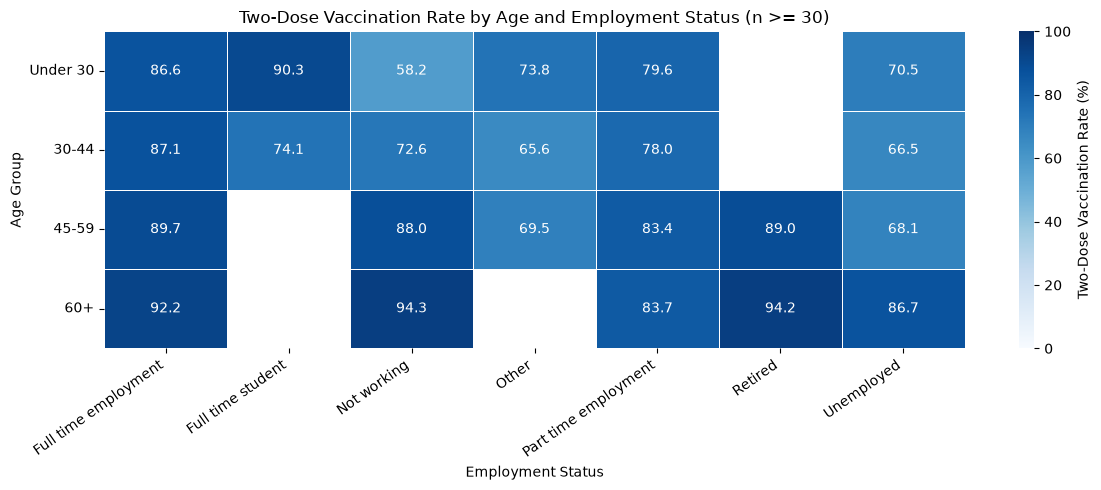

In [20]:
#EDA 9: Age × Employment Status vs Vaccination Status

#Step 1: Create age groups (if not already created)
eda_df["age_group"] = pd.cut(
    eda_df["age"],
    bins=[0, 29, 44, 59, float("inf")],
    labels=["Under 30", "30-44", "45-59", "60+"],
    include_lowest=True)

#Step 2: Calculate vaccination rates for each combination
age_employment_summary = eda_df.groupby(
    ["age_group", "employment_status"],
    observed=True
)["vac_binary"].agg(["count", "mean"]).reset_index()

age_employment_summary["Vaccination Rate (%)"] = (
    age_employment_summary["mean"] * 100)

print("Vaccination Rates by Age Group and Employment Status:")
print(age_employment_summary.to_string(index=False))


#Step 3: Create cross-tabulation of vaccination rates
rate_table = pd.crosstab(
    eda_df["age_group"],
    eda_df["employment_status"],
    values=eda_df["vac_binary"],
    aggfunc="mean") * 100

print("\nVaccination Rate Cross-tabulation (%):")
print(rate_table.round(2))


#Step 4: Create cross-tabulation of sample sizes
count_table = pd.crosstab(
    eda_df["age_group"],
    eda_df["employment_status"])

print("\nSample Size Cross-tabulation:")
print(count_table)


#Step 5: Mask groups with fewer than 30 observations
mask = count_table.reindex(
    index=rate_table.index,
    columns=rate_table.columns) < 30


#Step 6: Visualize vaccination rates using a heatmap
plt.figure(figsize=(12, 5))

sns.heatmap(
    rate_table,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    mask=mask,
    linewidths=0.5,
    cbar_kws={"label": "Two-Dose Vaccination Rate (%)"})

plt.title(
    "Two-Dose Vaccination Rate by Age and Employment Status (n >= 30)")
plt.xlabel("Employment Status")
plt.ylabel("Age Group")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## **[2]: Tuning the Model**

Our goal is to predict whether a respondent received at least two COVID-19 vaccine doses (Class 1) or fewer than two doses (Class 0). Because Class 1 makes up most of the dataset, we use **balanced accuracy** to select the model. Balanced accuracy gives equal importance to the recall of both classes, rather than mainly rewarding correct predictions for the larger class.

We choose hyperparameters using 5-fold cross-validation on the training set only. We also report regular accuracy, precision, recall, and F1 to better understand the model's strengths and limitations.
Through multiple iterations of feature selection and model evaluation, supported by findings from exploratory data analysis (EDA), we assessed different combinations of demographic and vaccination-related predictors. Variables such as region and gender showed limited additional predictive value and were therefore excluded from the selected feature set.

We selected five predictors for further model tuning:
- Vaccine trust (vac7_num): Respondents' trust in COVID-19 vaccines.
- Perceived vaccine protection (r1_8_num): Belief that vaccination provides personal protection.
- Age (age): Respondent's age.
- Household children (household_children): Number of children in the household.
- Employment status (employment_status): Respondent's employment category.

### 1. Preprocessing and cross-validation

KNN compares observations using distance. We standardize numerical variables, one-hot encode categorical variables, and fill missing values within the pipeline. This keeps preprocessing separate within each training fold.

We use stratified 5-fold cross-validation to keep the proportions of Class 0 and Class 1 similar across folds. The test set is kept separate until final evaluation.

The training dataset is highly imbalanced, with 4,447 fully vaccinated respondents (Class 1) compared to only 697 not fully vaccinated respondents (Class 0). To improve the identification of Class 0, we experimented with regular KNN, oversampling, and different undersampling ratios (0.6 and 1.0), alongside various predictor combinations and hyperparameters.

We explored partial undersampling (0.6) to reduce the dominance of Class 1 while retaining more observations than full undersampling. This approach increases the representation of Class 0 during training, with the aim of improving its recall while maintaining reasonable precision and overall model performance.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score,recall_score,precision_score,make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.under_sampling import RandomUnderSampler

numeric_features = ["vac7_num","r1_8_num", "age"]
categorical_features = ["household_children","employment_status"]

numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("numeric", numeric_pipeline, numeric_features), ("categorical", categorical_pipeline, categorical_features)])
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("undersampler", RandomUnderSampler(
        sampling_strategy=0.6,
        random_state=42
    )),
    ("knn", KNeighborsClassifier())
])
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Balanced accuracy selects the model; the other scores help explain its performance.
scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
    "f1_class1": "f1",
    "f1_class0": make_scorer(f1_score, pos_label=0),
    "recall_class0": make_scorer(recall_score, pos_label=0),
    "recall_class1": make_scorer(recall_score, pos_label=1),
    "precision_class0": make_scorer(
        precision_score, pos_label=0, zero_division=0
    ),
    "precision_class1": make_scorer(
        precision_score, pos_label=1, zero_division=0
    )
}

### 2. Hyperparameter tuning using 5-fold CV

We compare k = 1 to 51 and two voting methods: `uniform` and `distance`. This gives 102 combinations. GridSearchCV evaluates each combination using 5-fold cross-validation and selects the one with the highest mean balanced accuracy.

We also record training scores and the performance of both classes to understand how changing k affects the model.

In [27]:
k_values = np.arange(1, 52)
param_grid = {"knn__n_neighbors": k_values, "knn__weights": ["uniform", "distance"]}
grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="balanced_accuracy",
    cv=kfold,
    return_train_score=True,
    n_jobs=-1
)
grid_result = grid.fit(X_train, y_train)
print("Best parameters (balanced accuracy):", grid_result.best_params_)
print("Best mean CV balanced accuracy:", round(grid_result.best_score_, 4))

Best parameters (balanced accuracy): {'knn__n_neighbors': np.int64(8), 'knn__weights': 'uniform'}
Best mean CV balanced accuracy: 0.8208


### 3. Cross-Validation Results and Model Selection

We select the model with the highest average balanced accuracy across the five validation folds. This metric is the average recall of Class 0 and Class 1, so both vaccination groups matter equally.

We also show the regular accuracy and F1 scores for each class. Since most respondents are in Class 1, regular accuracy can be high even if the model misses many Class 0 respondents.
We use GridSearchCV to evaluate different values of k (1–51) and two weighting methods (uniform and distance-based). We also report overall accuracy, precision, recall, and F1 scores for both classes to better understand model performance.

Since most respondents belong to Class 1, overall accuracy can remain high even when the model fails to identify many Class 0 respondents. Therefore, we pay particular attention to Class 0 recall and precision to assess the trade-off between identifying not fully vaccinated individuals and minimizing incorrect Class 0 predictions.

In [31]:
results = pd.DataFrame(grid_result.cv_results_)
summary = results[[
    "param_knn__n_neighbors", "param_knn__weights",
    "mean_train_balanced_accuracy", "mean_test_balanced_accuracy", "std_test_balanced_accuracy",
    "mean_test_accuracy", "mean_test_f1_class1", "mean_test_f1_class0",
    "mean_test_precision_class1", "mean_test_recall_class1",
    "mean_test_precision_class0", "mean_test_recall_class0"
]].copy()
summary.columns = [
    "k", "weights", "Train Balanced Accuracy", "CV Balanced Accuracy",
    "CV SD", "CV Accuracy", "CV F1 Class 1", "CV F1 Class 0",
    "CV Precision Class 1", "CV Recall Class 1",
    "CV Precision Class 0", "CV Recall Class 0"
]
summary["k"] = summary["k"].astype(int)
summary = summary.sort_values("CV Balanced Accuracy", ascending=False)
selected_row = summary.loc[grid_result.best_index_]
print("Top 15 candidate settings by CV balanced accuracy:")
display(summary.head(15).round(4))
print("Selected candidate:")
display(summary.loc[[grid_result.best_index_]].round(4))

# An always-Class-1 model would get balanced accuracy = 0.5.
print("Always-Class-1 baseline balanced accuracy: 0.5000")


Top 15 candidate settings by CV balanced accuracy:


,k,weights,Train Balanced Accuracy,CV Balanced Accuracy,CV SD,CV Accuracy,CV F1 Class 1,CV F1 Class 0,CV Precision Class 1,CV Recall Class 1,CV Precision Class 0,CV Recall Class 0
14,8,uniform,0.8439,0.8208,0.0108,0.8429,0.9035,0.5773,0.9629,0.8511,0.4550,0.7906
6,4,uniform,0.8632,0.8179,0.0079,0.8128,0.8822,0.5444,0.9673,0.8109,0.4065,0.8250
58,30,uniform,0.8248,0.8167,0.0180,0.8672,0.9202,0.6040,0.9573,0.8860,0.5067,0.7475
10,6,uniform,0.8500,0.8166,0.0099,0.8315,0.8956,0.5618,0.9633,0.8370,0.4343,0.7963
78,40,uniform,0.8195,0.8163,0.0158,0.8738,0.9246,0.6127,0.9561,0.8952,0.5243,0.7374
68,35,uniform,0.8195,0.8160,0.0195,0.8754,0.9257,0.6148,0.9557,0.8975,0.5287,0.7346
70,36,uniform,0.8225,0.8154,0.0172,0.8711,0.9229,0.6081,0.9562,0.8918,0.5168,0.7389
18,10,uniform,0.8405,0.8152,0.0143,0.8478,0.9071,0.5786,0.9599,0.8599,0.4635,0.7705
94,48,uniform,0.8172,0.8148,0.0175,0.8764,0.9263,0.6153,0.9551,0.8993,0.5317,0.7303
82,42,uniform,0.8189,0.8146,0.0176,0.8740,0.9248,0.6117,0.9554,0.8961,0.5249,0.7331


Selected candidate:


,k,weights,Train Balanced Accuracy,CV Balanced Accuracy,CV SD,CV Accuracy,CV F1 Class 1,CV F1 Class 0,CV Precision Class 1,CV Recall Class 1,CV Precision Class 0,CV Recall Class 0
14,8,uniform,0.8439,0.8208,0.0108,0.8429,0.9035,0.5773,0.9629,0.8511,0.455,0.7906


Always-Class-1 baseline balanced accuracy: 0.5000


### 4. Accuracy, Precision, Recall, F1, and Balanced Accuracy

We calculate these metrics using out-of-fold predictions on the training data:

- **Accuracy:** the percentage of all predictions that are correct.
- **Precision (Class 1):** of those predicted to have at least two doses, how many actually did.
- **Recall (Class 1):** of those who actually had at least two doses, how many we identified.
- **F1 (Class 1):** combines Class 1 precision and recall.
- **Balanced accuracy:** the average recall of Class 0 and Class 1.
- **Precision (Class 0):** of those predicted to have fewer than two doses, how many actually did.
- **Recall (Class 0):** of those who actually had fewer than two doses, how many we identified.
- **F1 (Class 0):** combines Class 0 precision and recall.

We use **balanced accuracy for tuning** because the two classes have very different sizes. We still report F1 and Class 0 recall because they show whether the model performs well beyond the majority class. These are training-set CV diagnostics, not final test scores.

In [32]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score
)

metric_model = clone(grid_result.best_estimator_)
cv_predictions = cross_val_predict(metric_model, X_train, y_train, cv=kfold, n_jobs=-1)

metric_table = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced Accuracy", "Precision (Class 1)",
               "Recall (Class 1)", "F1 (Class 1)",
               "Precision (Class 0)", "Recall (Class 0)", "F1 (Class 0)"],
    "Out-of-fold training estimate": [
        accuracy_score(y_train, cv_predictions),
        balanced_accuracy_score(y_train, cv_predictions),
        precision_score(y_train, cv_predictions, pos_label=1, zero_division=0),
        recall_score(y_train, cv_predictions, pos_label=1, zero_division=0),
        f1_score(y_train, cv_predictions, pos_label=1, zero_division=0),
        precision_score(y_train, cv_predictions, pos_label=0, zero_division=0),
        recall_score(y_train, cv_predictions, pos_label=0, zero_division=0),
        f1_score(y_train, cv_predictions, pos_label=0, zero_division=0)
    ]
})

display(metric_table.round(4))

# The parameters were selected using the same training sample, so these are diagnostics,
# not an independent estimate of final performance.


,Metric,Out-of-fold training estimate
0,Accuracy,0.8429
1,Balanced Accuracy,0.8208
2,Precision (Class 1),0.9629
3,Recall (Class 1),0.8511
4,F1 (Class 1),0.9036
5,Precision (Class 0),0.4542
6,Recall (Class 0),0.7905
7,F1 (Class 0),0.5770


### 5. Choice of k: balancing noise and predictor information

A small k uses only a few nearby observations, so it can capture local differences but may also be sensitive to noise. A large k gives smoother predictions, but with our imbalanced data it can favor Class 1 and miss more Class 0 respondents.

We compare training and cross-validation balanced accuracy to assess potential overfitting, alongside precision, recall, and F1 scores for both classes. We selected k = 8 with uniform weighting based on the highest cross-validation balanced accuracy, which gives equal importance to both vaccination classes. Given the substantial class imbalance, we also applied partial undersampling (0.6 ratio) to reduce the dominance of Class 1 and improve the model's ability to identify Class 0 respondents. This was particularly important because incorrectly predicting that an individual is fully vaccinated when they are not may have greater consequences in the context of this project. Therefore, we also examined Class 0 precision, recall, and F1 scores to assess this trade-off. Finally, we compared training and cross-validation balanced accuracy to assess potential overfitting, as smaller values of k may be more sensitive to individual observations.

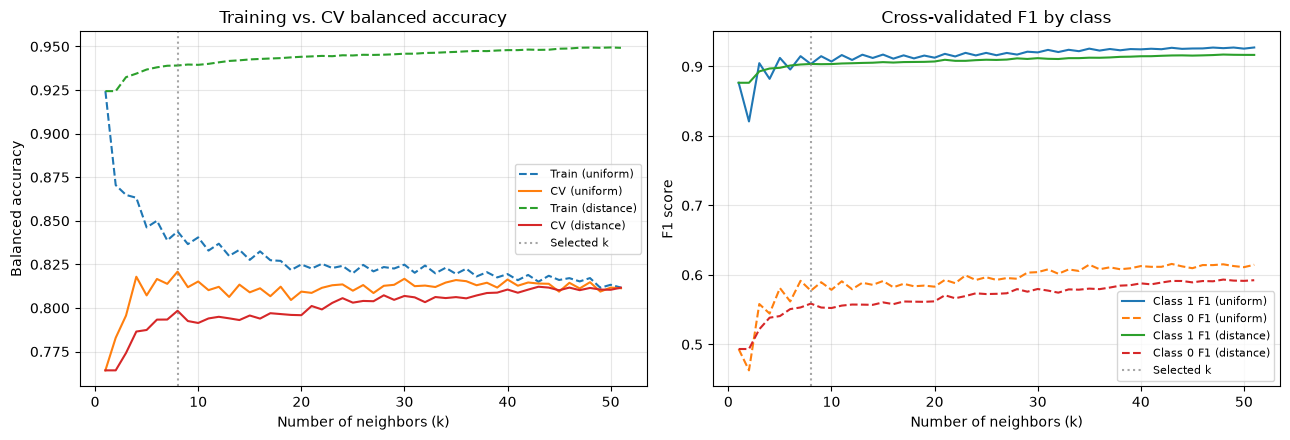

Selected k: 8
Selected weights: uniform
Selected CV balanced accuracy: 0.8208
Selected CV accuracy: 0.8429
Selected Class 0 CV F1: 0.5773
Train–CV balanced accuracy gap: 0.0231


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for weight in ["uniform", "distance"]:
    subset = summary[summary["weights"] == weight].sort_values("k")
    axes[0].plot(subset["k"], subset["Train Balanced Accuracy"], "--", label=f"Train ({weight})")
    axes[0].plot(subset["k"], subset["CV Balanced Accuracy"], label=f"CV ({weight})")
    axes[1].plot(subset["k"], subset["CV F1 Class 1"], label=f"Class 1 F1 ({weight})")
    axes[1].plot(subset["k"], subset["CV F1 Class 0"], "--", label=f"Class 0 F1 ({weight})")
for ax in axes:
    ax.axvline(int(selected_row["k"]), color="gray", linestyle=":", alpha=0.7, label="Selected k")
    ax.set_xlabel("Number of neighbors (k)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Balanced accuracy")
axes[1].set_ylabel("F1 score")
axes[0].set_title("Training vs. CV balanced accuracy")
axes[1].set_title("Cross-validated F1 by class")
plt.tight_layout()
plt.show()

print("Selected k:", int(selected_row["k"]))
print("Selected weights:", selected_row["weights"])
print("Selected CV balanced accuracy:", round(selected_row["CV Balanced Accuracy"], 4))
print("Selected CV accuracy:", round(selected_row["CV Accuracy"], 4))
print("Selected Class 0 CV F1:", round(selected_row["CV F1 Class 0"], 4))
print("Train–CV balanced accuracy gap:", round(selected_row["Train Balanced Accuracy"] - selected_row["CV Balanced Accuracy"], 4))

### 6. Additional experiments

We also explored different predictor combinations, including removing individual variables and adding vaccination-related attitudes, to evaluate their contribution to model performance. We also compared regular KNN, random oversampling, and different undersampling ratios (0.6 and 1.0) to address class imbalance and improve Class 0 predictions.

Based on our EDA findings and cross-validation results, we retained five predictors: vaccine trust, perceived vaccine protection, age, household children, and employment status. We selected partial undersampling (0.6 ratio) to improve Class 0 identification while preserving more majority-class observations than full undersampling. The final model uses k = 8 with uniform weighting, selected based on cross-validation balanced accuracy.

### 7. Final Model Selection and Interpretation

Using stratified 5-fold cross-validation, we evaluated k values from 1 to 51 with uniform and distance-based weighting. We selected **k = 8** with uniform weighting, which achieved the highest cross-validation balanced accuracy of 0.8208.

The model uses five predictors and partial undersampling (0.6 ratio) to reduce the influence of the majority class during training. While balanced accuracy gives equal importance to both classes, we also considered Class 0 precision, recall, and F1 scores, as incorrectly classifying not fully vaccinated individuals as fully vaccinated may be more consequential in this context.

The relatively small training–validation balanced accuracy gap (0.0231) suggests limited evidence of severe overfitting, although smaller values of k may be more sensitive to noise. Final performance will be assessed using the untouched test set.

The model may help the Public Health Agency of Canada better understand vaccination patterns. However, it should not be used alone to identify individuals requiring additional vaccination outreach, especially if Class 0 recall remains low on the test set, as this would indicate that the model fails to identify a substantial proportion of respondents who are not fully vaccinated.

Final k: 8
Final weights: uniform

Exploratory Class 0 threshold comparison:


,Threshold,Balanced Accuracy,Class 0 Precision,Class 0 Recall,Class 0 F1,Class 1 Precision,Class 1 Recall,Class 1 F1
0,0.20,0.8098,0.3252,0.9182,0.4803,0.9821,0.7014,0.8183
1,0.25,0.8098,0.3252,0.9182,0.4803,0.9821,0.7014,0.8183
2,0.30,0.8203,0.3870,0.8522,0.5323,0.9715,0.7884,0.8704
3,0.35,0.8203,0.3870,0.8522,0.5323,0.9715,0.7884,0.8704
4,0.40,0.8208,0.4542,0.7905,0.5770,0.9629,0.8511,0.9036
5,0.45,0.8208,0.4542,0.7905,0.5770,0.9629,0.8511,0.9036
6,0.50,0.8208,0.4542,0.7905,0.5770,0.9629,0.8511,0.9036
7,0.55,0.7960,0.5094,0.6973,0.5887,0.9496,0.8948,0.9214
8,0.60,0.7960,0.5094,0.6973,0.5887,0.9496,0.8948,0.9214


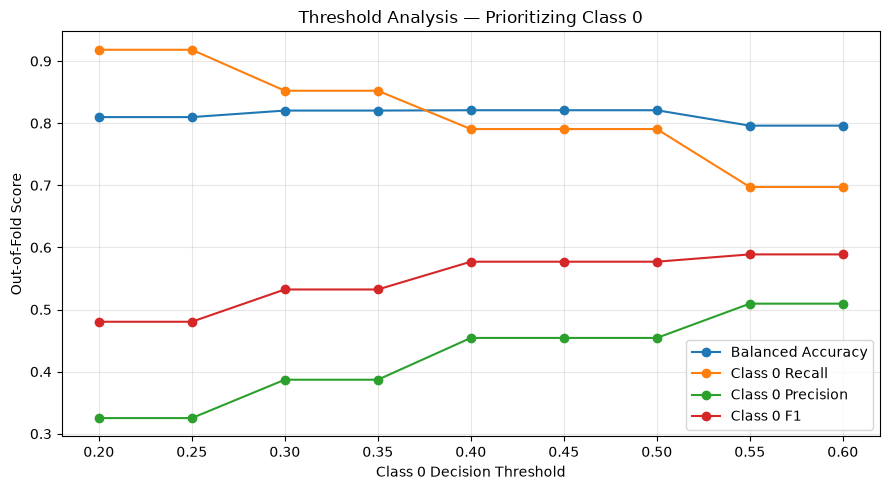

Final prediction rule: default KNN voting


In [36]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score, balanced_accuracy_score

# Fit the CV-selected model
best_model = clone(grid_result.best_estimator_)
best_model.fit(X_train, y_train)
print("Final k:", best_model.named_steps["knn"].n_neighbors)
print("Final weights:", best_model.named_steps["knn"].weights)

# Out-of-fold probabilities for Class 0
cv_probs = cross_val_predict(clone(best_model), X_train, y_train, cv=kfold, method="predict_proba", n_jobs=-1)
class0_col = list(best_model.classes_).index(0)
cv_prob_class0 = cv_probs[:, class0_col]

# Explore Class 0 decision thresholds
threshold_rows = []

for threshold in np.round(np.arange(0.20, 0.61, 0.05), 2):
    pred = np.where(cv_prob_class0 >= threshold, 0, 1)
    threshold_rows.append({
        "Threshold": threshold,
        "Balanced Accuracy": balanced_accuracy_score(y_train, pred),
        "Class 0 Precision": precision_score(y_train, pred, pos_label=0, zero_division=0),
        "Class 0 Recall": recall_score(y_train, pred, pos_label=0, zero_division=0),
        "Class 0 F1": f1_score(y_train, pred, pos_label=0, zero_division=0),
        "Class 1 Precision": precision_score(y_train, pred, pos_label=1, zero_division=0),
        "Class 1 Recall": recall_score(y_train, pred, pos_label=1, zero_division=0),
        "Class 1 F1": f1_score(y_train, pred, pos_label=1, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
print("\nExploratory Class 0 threshold comparison:")
display(threshold_df.round(4))

# Plot threshold performance
plt.figure(figsize=(9, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Balanced Accuracy"], marker="o", label="Balanced Accuracy")
plt.plot(threshold_df["Threshold"], threshold_df["Class 0 Recall"], marker="o", label="Class 0 Recall")
plt.plot(threshold_df["Threshold"], threshold_df["Class 0 Precision"], marker="o", label="Class 0 Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Class 0 F1"], marker="o", label="Class 0 F1")

plt.xlabel("Class 0 Decision Threshold")
plt.ylabel("Out-of-Fold Score")
plt.title("Threshold Analysis — Prioritizing Class 0")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Final model still uses default KNN voting
print("Final prediction rule: default KNN voting")


## **[3]: Evaluating the Model**

We evaluate our fitted model with k=8 below by showing the classification matrix on the test set, the classification metrics (accuracy, precision, recall and F1). In addition, we plot the ROC Curve and report its AUC to assess the model's ability to distinguish the vaccination classes. We also pay closer attention to Class 0 performance, as correctly identifying respondents who are not fully vaccinated is an important consideration for our project objective.

### 1. Confusion Matrix

Below,  confusion matrix shows that 920 out of 1,286 test observations (71.54%) were correctly classified as fully vaccinated (Class 1). Additionally, 34 observations (2.64% of the test set) were incorrectly classified as fully vaccinated despite actually belonging to Class 0. We pay particular attention to these misclassifications, as incorrectly identifying not fully vaccinated individuals as fully vaccinated may have greater consequences for our project's public health objective. Additionally, 192 out of 1,286 test observations (14.93%) were incorrectly classified as not fully vaccinated when they were actually fully vaccinated. While these misclassifications are important to consider, they are less consequential to our project objective than incorrectly identifying not fully vaccinated individuals as fully vaccinated, which could result in missed opportunities for vaccination outreach. Despite the class imbalance and the relatively small number of not fully vaccinated respondents, the model correctly classified 140 out of 1,286 test observations (10.89%) as not fully vaccinated (Class 0). This suggests that the model can identify a substantial proportion of the minority class, despite its lower representation in the dataset.

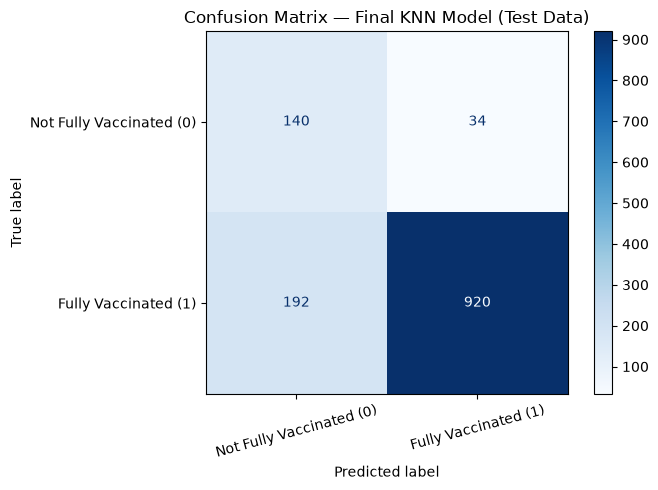

In [37]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, accuracy_score,
    balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    RocCurveDisplay
)

# Final model selected by GridSearchCV
final_model = grid_result.best_estimator_

# Predictions on untouched test data
y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, list(final_model.classes_).index(1)]

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Fully Vaccinated (0)", "Fully Vaccinated (1)"]
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Final KNN Model (Test Data)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### 2. Classification Metrics

We obtain a **test balanced accuracy of 81.6%**. This indicates that both classes are distinguished reasonably well, despite the significant class imbalance in the original data. 
While Class 0 recall is approximately 80.5%, precision is substantially lower at 42.2%. This highlights the model's tendency to overclassify respondents as Class 0, as only 42.2% of those predicted to be not fully vaccinated actually belong to this class. This trade-off reflects the model's emphasis on identifying not fully vaccinated individuals, at the expense of increased misclassification of fully vaccinated respondents. Class 1 (fully vaccinated) achieved a precision of 96.4% and recall of approximately 83%, indicating that predictions of full vaccination were highly reliable, although the model failed to identify approximately 17.3% of respondents who were actually fully vaccinated, at the cost of leveraging class 0 identification.

The test balanced accuracy (81.6%) was very similar to the cross validation balanced accuracy estimated (82.08%). This suggests absence of overfitting in the model and that the model performs relatively as expected to unseen data, from the same dataset. 

In [38]:

# Classification report
print("Final KNN Test Classification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Not Fully Vaccinated (0)", "Fully Vaccinated (1)"],
    digits=4,
    zero_division=0
))

# Summary table
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred),
    "Precision Class 0": precision_score(y_test, y_test_pred, pos_label=0, zero_division=0),
    "Recall Class 0": recall_score(y_test, y_test_pred, pos_label=0, zero_division=0),
    "F1 Class 0": f1_score(y_test, y_test_pred, pos_label=0, zero_division=0),
    "Precision Class 1": precision_score(y_test, y_test_pred, pos_label=1, zero_division=0),
    "Recall Class 1": recall_score(y_test, y_test_pred, pos_label=1, zero_division=0),
    "F1 Class 1": f1_score(y_test, y_test_pred, pos_label=1, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, y_test_prob)
}

test_metrics_df = pd.DataFrame(
    test_metrics.items(),
    columns=["Metric", "Test Score"]
)

display(test_metrics_df.round(4))


Final KNN Test Classification Report:
                          precision    recall  f1-score   support

Not Fully Vaccinated (0)     0.4217    0.8046    0.5534       174
    Fully Vaccinated (1)     0.9644    0.8273    0.8906      1112

                accuracy                         0.8243      1286
               macro avg     0.6930    0.8160    0.7220      1286
            weighted avg     0.8909    0.8243    0.8450      1286



,Metric,Test Score
0,Accuracy,0.8243
1,Balanced Accuracy,0.8160
2,Precision Class 0,0.4217
3,Recall Class 0,0.8046
4,F1 Class 0,0.5534
5,Precision Class 1,0.9644
6,Recall Class 1,0.8273
7,F1 Class 1,0.8906
8,ROC AUC,0.8932


### 3. ROC Curve and AUC

We plot the ROC curve below and observe that the model performs substantially better than a random classifier, as the curve lies above the diagonal reference line and approaches the top-left corner (0,1). This indicates that the model can distinguish between fully vaccinated and not fully vaccinated respondents.

The model achieves an AUC of 0.89, indicating good classification performance across different decision thresholds. However, given the class imbalance in the dataset, ROC AUC alone may provide an overly optimistic impression of model performance, as it does not directly account for precision in the minority class. Therefore, we also examine **Class 0 precision, recall, and F1 scores** to better assess the model's ability to identify respondents who are not fully vaccinated.

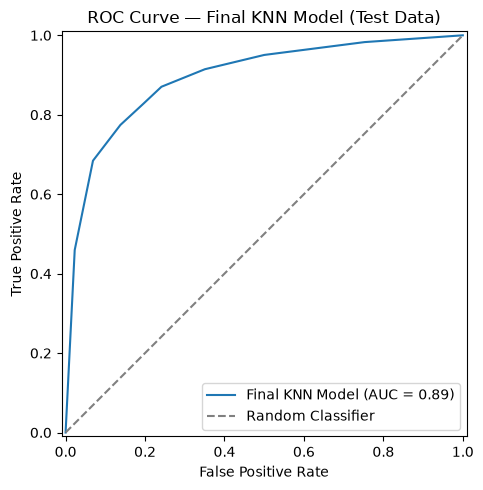

Test ROC AUC: 0.8932


In [39]:

# ROC curve for the final model
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob,
    pos_label=1,
    name="Final KNN Model",
    ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier")

ax.set_title("ROC Curve — Final KNN Model (Test Data)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

print("Test ROC AUC:", round(roc_auc_score(y_test, y_test_prob), 4))
